# Fluxo experimental de classificação

## 1. Carregamento inicial
### 1.1 Importação das bibliotecas

Esta etapa verifica o arquivo, o esquema e a qualidade básica antes de qualquer modelagem. O objetivo é tornar explícito o que sabemos dos dados, não selecionar um modelo nem inferir significado clínico dos nomes codificados.

Coloque `final_treino_val.csv` em `data/raw/`. O arquivo é ignorado pelo Git. O regulamento define `desfecho=1` como classe positiva e `id` como identificador. Não use `id` como atributo preditor.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.ensemble import (
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

import json
import sklearn
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold



In [3]:
sns.set_theme(style="whitegrid")
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "raw").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "final_treino_val.csv"
TARGET = "desfecho"
ID_COLUMN = "id"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Arquivo não encontrado: {DATA_PATH.resolve()}. "
        "Copie o CSV local para data/raw/ sem adicioná-lo ao Git."
    )

df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip().str.lower()
df_dev, df_holdout = train_test_split(
    df, test_size=0.20, stratify=df[TARGET], random_state=42
)
print(f"Dimensões: {df.shape[0]:,} linhas x {df.shape[1]} colunas")
print(f"Desenvolvimento: {len(df_dev):,}; holdout local reservado: {len(df_holdout):,}")
# A amostra de linhas não é exibida; as inspeções seguintes são agregadas.

## 2. Preparação dos dados
### 2.1 Tratamento de inconsistências

Vamos confirmar a presença do identificador e do alvo, verificar os rótulos observados, valores ausentes, duplicatas e cardinalidade. Tipos inteiros, por si só, não significam que uma variável deva ser tratada como contínua; a classificação de tipos deve considerar o regulamento.

In [5]:
required_columns = {ID_COLUMN, TARGET}
missing_required = required_columns - set(df.columns)
if missing_required:
    raise ValueError(f"Colunas obrigatórias ausentes: {sorted(missing_required)}")

print("Tipos de dados:")
display(df.dtypes.rename("dtype").to_frame())

quality = pd.Series(
    {
        "linhas": len(df),
        "colunas": df.shape[1],
        "linhas duplicadas": int(df.duplicated().sum()),
        "IDs ausentes": int(df[ID_COLUMN].isna().sum()),
        "IDs duplicados": int(df[ID_COLUMN].duplicated().sum()),
        "alvos ausentes": int(df[TARGET].isna().sum()),
    },
)
display(quality.rename("valor").to_frame())
print("Valores ausentes por coluna:")
display(df.isna().sum().sort_values(ascending=False).rename("ausentes").to_frame())

observed_target = set(df[TARGET].dropna().unique())
if not observed_target.issubset({0, 1}):
    raise ValueError(f"Rótulos inesperados em {TARGET}: {observed_target}")
print("Rótulos observados:", sorted(observed_target))

In [6]:
feature_columns = [c for c in df.columns if c not in {ID_COLUMN, TARGET}]
cardinality = df_dev[feature_columns].nunique(dropna=False).sort_values()
display(cardinality.rename("valores distintos").to_frame())

target_counts = df_dev[TARGET].value_counts(dropna=False).sort_index()
target_summary = pd.DataFrame(
    {"contagem": target_counts, "proporcao": target_counts / len(df_dev)}
)
display(target_summary)

ax = sns.countplot(data=df_dev, x=TARGET, order=[0, 1], color="steelblue")
ax.set(title="Distribuição do desfecho", xlabel="Desfecho (0 = cura, 1 = óbito)", ylabel="Número de registros")
plt.tight_layout()
plt.show()

### 2.2 Criação das variáveis

Esta etapa registra a cardinalidade e estatísticas descritivas sem atribuir significado clínico aos códigos. Neste primeiro ciclo, não criaremos variáveis derivadas: o significado das categorias não foi divulgado e engenharia de atributos deve ser motivada e avaliada dentro do protocolo.

Uma diferença observada entre grupos é descritiva e não demonstra causalidade. Nenhuma decisão de modelagem ou limiar deve ser tomada com base no conjunto de teste final.

In [8]:
display(df_dev[feature_columns].describe(include="all").T)

# Proporções do alvo por valor observado; útil para inspeção, sem interpretação causal.
for column in feature_columns:
    table = pd.crosstab(df_dev[column], df_dev[TARGET], normalize="index")
    table.columns = [f"proporcao_desfecho_{value}" for value in table.columns]
    print(f"{column} (n valores={df_dev[column].nunique(dropna=False)})")
    display(table)

### 2.3 Pré-processamento

Para os modelos, as variáveis nominais serão codificadas com one-hot encoding e as quantitativas tratadas numericamente. Qualquer imputação, codificação ou escala será ajustada dentro de um `Pipeline`/`ColumnTransformer` durante cada fold, evitando que informação dos folds de validação influencie o pré-processamento. A auditoria atual não encontrou ausências, mas os imputadores permitem tratar ausências se surgirem. Este pré-processador ainda não foi ajustado; na etapa 4 ele será combinado com cada estimador em um `Pipeline`, para que cada fold aprenda as transformações apenas no próprio treino.



In [10]:
# Tipos definidos pelo regulamento e conferidos contra o esquema recebido.
binary_features = (
    [f"dadoclin{i}" for i in range(1, 15)]
    + ["sociodemografico1", "sociodemografico2"]
    + [f"comorbidade{i}" for i in range(1, 8)]
)
numeric_features = ["sociodemografico3"]
nominal_features = ["sociodemografico4", "sociodemografico5"]
expected_features = set(binary_features + numeric_features + nominal_features)
if set(feature_columns) != expected_features:
    raise ValueError("O esquema das variáveis preditoras difere do esperado; revisar antes de modelar.")

invalid_binary_values = {
    column: sorted(set(df[column].dropna().unique()) - {0, 1})
    for column in binary_features
    if not set(df[column].dropna().unique()).issubset({0, 1})
}
if invalid_binary_values:
    raise ValueError(f"Valores fora de 0/1 em variáveis binárias: {invalid_binary_values}")

binary_pipeline = SimpleImputer(strategy="most_frequent")
numeric_pipeline = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
)
nominal_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)
preprocessor = ColumnTransformer(
    transformers=[
        ("binary", binary_pipeline, binary_features),
        ("numeric", numeric_pipeline, numeric_features),
        ("nominal", nominal_pipeline, nominal_features),
    ],
    remainder="drop",
)
print("Pré-processador criado, ainda não ajustado.")


## 3. Protocolo de avaliação

**Estratégia:** reservar uma partição estratificada de 20% como holdout final local, com `random_state=42`. Os 80% restantes serão usados para desenvolvimento e validação cruzada estratificada de 5 folds, com embaralhamento e semente fixa. A divisão é feita logo após o carregamento; as análises de relação entre atributos e alvo abaixo usam apenas o desenvolvimento.

**Seleção:** ROC-AUC média nos folds de validação (`scoring="roc_auc"`), coerente com a métrica principal do regulamento. O spot-check inicial usará configurações previamente definidas, sem busca extensa. Se houver ajuste posterior de hiperparâmetros, a CV será tratada como etapa de seleção. O holdout será usado ao final para avaliar o fluxo selecionado, não para escolher entre vários modelos.

**Métricas de avaliação:** ROC-AUC como critério principal; definir o limiar a partir de predições out-of-fold do desenvolvimento e então reportar sensibilidade, especificidade, LR−, F1 e matriz de confusão no holdout. AUC mede ordenação das probabilidades e não depende de limiar; LR− e F1 dependem.

**Prevenção de data leakage:** excluir `id` de `X`; separar holdout antes das análises de associação e de qualquer ajuste; combinar o pré-processador e cada estimador em um `Pipeline` e passar esse pipeline à validação cruzada, para ajustar transformações somente no treino de cada fold; não usar o teste oficial nem seus rótulos para decisões. Registros duplicados ou inconsistências serão investigados antes de qualquer remoção, sem descarte automático.

In [12]:
predictor_columns = binary_features + numeric_features + nominal_features
X_dev = df_dev[predictor_columns].copy()
X_holdout = df_holdout[predictor_columns].copy()
y_dev = df_dev[TARGET].astype(int).copy()
y_holdout = df_holdout[TARGET].astype(int).copy()
ids = df[ID_COLUMN].copy()  # Guardado à parte para rastreio e submissão.

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(f"Desenvolvimento: {len(X_dev):,}; holdout local reservado: {len(X_holdout):,}")
print("Preditores:", X_dev.shape[1], "| identificador fora de X:", ID_COLUMN not in X_dev.columns)


## 4. Spot-checking dos algoritmos

### 4.1 Definição dos modelos e hiperparâmetros

Vamos comparar seis famílias em uma busca limitada e pré-definida: regressão logística como referência; Random Forest e Extra Trees para bagging; Gradient Boosting e HistGradientBoosting para boosting; e SVC com kernel RBF como método baseado em margem. Os ensembles de árvores e o SVC são candidatos capazes de capturar relações não lineares; essa é uma hipótese para experimentar, não uma garantia de melhor AUC.

A busca aleatória usa listas explícitas de valores, `scoring="roc_auc"` e semente fixa. Serão testadas 8 configurações em cada busca interna da validação aninhada e 15 na busca final em todo o desenvolvimento. O número de árvores fica fixo em 400 para Random Forest e Extra Trees, evitando gastar orçamento em um parâmetro cuja função principal é estabilizar o ensemble.

**Controle de overfitting:** a validação externa estratificada de 5 folds estima o desempenho de cada família; em cada fold externo, uma busca interna estratificada de 3 folds seleciona hiperparâmetros usando apenas o treino externo. Esse desenho separa seleção e avaliação e reduz o viés otimista de reportar a mesma CV usada para escolher hiperparâmetros. Depois, uma busca final ajusta os hiperparâmetros no conjunto de desenvolvimento inteiro. O holdout de 20% não participa de nenhuma busca.

In [14]:
models = {
    "logistic_regression": LogisticRegression(
        solver="lbfgs", l1_ratio=0.0, max_iter=3000, random_state=42
    ),
    "random_forest": RandomForestClassifier(
        n_estimators=400, random_state=42, n_jobs=1
    ),
    "extra_trees": ExtraTreesClassifier(
        n_estimators=400, random_state=42, n_jobs=1
    ),
    "gradient_boosting": GradientBoostingClassifier(random_state=42),
    "hist_gradient_boosting": HistGradientBoostingClassifier(
        random_state=42, early_stopping=False
    ),
    "svc_rbf": SVC(kernel="rbf"),
}

search_spaces = {
    "logistic_regression": {
        "model__C": [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0],
        "model__class_weight": [None, "balanced"],
    },
    "random_forest": {
        "model__max_depth": [None, 6, 10, 16],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4, 8, 16],
        "model__max_features": ["sqrt", 0.5, 0.8, 1.0],
        "model__class_weight": [None, "balanced_subsample"],
    },
    "extra_trees": {
        "model__max_depth": [None, 6, 10, 16],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4, 8, 16],
        "model__max_features": ["sqrt", 0.5, 0.8, 1.0],
        "model__class_weight": [None, "balanced"],
    },
    "gradient_boosting": {
        "model__n_estimators": [100, 200, 300],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [1, 2, 3],
        "model__min_samples_leaf": [5, 10, 20],
        "model__subsample": [0.7, 0.9, 1.0],
    },
    "hist_gradient_boosting": {
        "model__max_iter": [100, 200, 300, 500],
        "model__learning_rate": [0.03, 0.05, 0.08, 0.1],
        "model__max_leaf_nodes": [7, 15, 31],
        "model__min_samples_leaf": [10, 20, 30, 50],
        "model__l2_regularization": [0.0, 0.1, 1.0, 5.0],
    },
    "svc_rbf": {
        "model__C": [0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0],
        "model__gamma": ["scale", 0.001, 0.01, 0.1],
        "model__class_weight": [None, "balanced"],
    },
}

assert set(models) == set(search_spaces)
print(f"Famílias: {len(models)} | configurações por busca interna: 8 | busca final: 15")

### 4.2 Execução dos algoritmos

Cada busca recebe uma `Pipeline` nova com o pré-processador. O `RandomizedSearchCV` clona e ajusta a pipeline dentro de cada fold, mantendo imputação, escala e one-hot encoding restritos ao treino daquele fold. A AUC externa é calculada em observações que não participaram nem do ajuste nem da escolha dos hiperparâmetros daquele fold.

A tabela de AUC aninhada é a comparação menos enviesada entre as famílias. A AUC da busca final nos dados de desenvolvimento serve apenas para escolher parâmetros e não deve ser apresentada como desempenho final. O SVC usa `decision_function` para calcular AUC; se for selecionado, a etapa de submissão deverá calibrar probabilidades usando apenas desenvolvimento. O holdout local permanece reservado para avaliar a solução escolhida.

In [16]:
N_ITER_NESTED = 8
N_ITER_FINAL = 15
INNER_SPLITS = 3
outer_cv = cv  # 5 folds estratificados, random_state=42, definidos no protocolo.

nested_scores = {name: [] for name in models}
nested_fold_params = {name: [] for name in models}

for model_name, model in models.items():
    print(f"Validação aninhada: {model_name}", flush=True)
    for fold_number, (train_idx, valid_idx) in enumerate(outer_cv.split(X_dev, y_dev), start=1):
        X_outer_train = X_dev.iloc[train_idx]
        y_outer_train = y_dev.iloc[train_idx]
        X_outer_valid = X_dev.iloc[valid_idx]
        y_outer_valid = y_dev.iloc[valid_idx]

        inner_cv = StratifiedKFold(
            n_splits=INNER_SPLITS, shuffle=True, random_state=100 + fold_number
        )
        pipeline = Pipeline(
            steps=[("preprocessor", clone(preprocessor)), ("model", clone(model))]
        )
        search = RandomizedSearchCV(
            estimator=pipeline,
            param_distributions=search_spaces[model_name],
            n_iter=N_ITER_NESTED,
            scoring="roc_auc",
            cv=inner_cv,
            refit=True,
            random_state=42 + fold_number,
            n_jobs=-1,
            error_score="raise",
            return_train_score=False,
        )
        search.fit(X_outer_train, y_outer_train)

        fitted = search.best_estimator_
        if hasattr(fitted, "predict_proba"):
            outer_scores = fitted.predict_proba(X_outer_valid)[:, 1]
        else:
            outer_scores = fitted.decision_function(X_outer_valid)
        nested_scores[model_name].append(
            float(roc_auc_score(y_outer_valid, outer_scores))
        )
        nested_fold_params[model_name].append(
            {key: value.item() if hasattr(value, "item") else value
             for key, value in search.best_params_.items()}
        )
        print(f"  fold {fold_number}: AUC externa={nested_scores[model_name][-1]:.4f}", flush=True)

nested_summary = pd.DataFrame(
    [
        {
            "modelo": name,
            "auc_externa_media": np.mean(scores),
            "auc_externa_dp": np.std(scores, ddof=1),
            "auc_por_fold": scores,
        }
        for name, scores in nested_scores.items()
    ]
).sort_values("auc_externa_media", ascending=False).reset_index(drop=True)

display(nested_summary)

# Busca final dos hiperparâmetros em todo o desenvolvimento; o holdout não é usado.
final_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
final_searches = {}
for model_name, model in models.items():
    print(f"Busca final no desenvolvimento: {model_name}", flush=True)
    pipeline = Pipeline(
        steps=[("preprocessor", clone(preprocessor)), ("model", clone(model))]
    )
    final_search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=search_spaces[model_name],
        n_iter=N_ITER_FINAL,
        scoring="roc_auc",
        cv=final_cv,
        refit=True,
        random_state=2026,
        n_jobs=-1,
        error_score="raise",
        return_train_score=False,
    )
    final_search.fit(X_dev, y_dev)
    final_searches[model_name] = final_search
    print(f"  melhor AUC de seleção CV={final_search.best_score_:.4f}", flush=True)

stage4_results = {
    "protocol": {
        "scikit_learn_version": sklearn.__version__,
        "positive_class": 1,
        "selection_metric": "roc_auc",
        "outer_cv": {"type": "StratifiedKFold", "n_splits": 5, "shuffle": True, "random_state": 42},
        "inner_cv": {"type": "StratifiedKFold", "n_splits": INNER_SPLITS, "shuffle": True, "random_state": "100 + outer fold"},
        "nested_random_search_iterations_per_fold": N_ITER_NESTED,
        "final_development_search_iterations": N_ITER_FINAL,
        "development_rows": int(len(X_dev)),
        "holdout_reserved_rows": int(len(X_holdout)),
        "holdout_used_for_model_selection_or_scoring": False,
        "preprocessing_inside_pipeline": True,
    },
    "nested_cv": {
        name: {
            "outer_auc_by_fold": scores,
            "outer_auc_mean": float(np.mean(scores)),
            "outer_auc_std": float(np.std(scores, ddof=1)),
            "best_params_by_outer_fold": nested_fold_params[name],
        }
        for name, scores in nested_scores.items()
    },
    "best_params_on_full_development": {
        name: {
            "best_cv_auc_for_selection_only": float(search.best_score_),
            "best_params": {
                key: value.item() if hasattr(value, "item") else value
                for key, value in search.best_params_.items()
            },
        }
        for name, search in final_searches.items()
    },
    "search_spaces": search_spaces,
}

RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)
RESULTS_PATH = RESULTS_DIR / "stage4_model_search.json"
RESULTS_PATH.write_text(
    json.dumps(stage4_results, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(f"Resultados e hiperparâmetros salvos em: {RESULTS_PATH}")

## 5. Resultados

A comparação entre famílias usará as AUCs externas da validação aninhada, não as AUCs da busca final no desenvolvimento (estas foram usadas para selecionar parâmetros e tendem a ser otimistas). A família selecionada para a avaliação local será a de maior AUC externa média, conforme o protocolo. Como as médias estão próximas, o resultado será descrito como candidato, sem afirmar superioridade estatística.

O holdout será usado para avaliar somente esse candidato. Antes disso, o limiar de classificação será escolhido com as probabilidades out-of-fold do desenvolvimento, minimizando LR− e, entre empates, maximizando F1, como priorizam os critérios de desempate da competição. O holdout não será usado para ajustar limiar ou hiperparâmetros.

### 5.1 Tabelas comparativas

A primeira tabela compara as famílias pela AUC externa aninhada; a segunda registra os melhores parâmetros encontrados na busca final. A tabela seguinte apresenta as métricas do candidato selecionado no holdout.

In [18]:
stage4_path = PROJECT_ROOT / "results" / "stage4_model_search.json"
stage4_results = json.loads(stage4_path.read_text(encoding="utf-8"))

nested_rows = []
for model_name, result in stage4_results["nested_cv"].items():
    fold_aucs = result["outer_auc_by_fold"]
    nested_rows.append(
        {
            "Modelo": model_name,
            "AUC externa média": result["outer_auc_mean"],
            "DP entre folds": result["outer_auc_std"],
            "AUC mínima": min(fold_aucs),
            "AUC máxima": max(fold_aucs),
        }
    )
nested_table = pd.DataFrame(nested_rows).sort_values(
    "AUC externa média", ascending=False
).reset_index(drop=True)
display(nested_table.round(4))

# Esta tabela documenta a busca; sua AUC não é uma estimativa final de generalização.
parameter_rows = []
for model_name, result in stage4_results["best_params_on_full_development"].items():
    parameter_rows.append(
        {
            "Modelo": model_name,
            "AUC CV para seleção (não final)": result["best_cv_auc_for_selection_only"],
            "Melhores parâmetros": json.dumps(result["best_params"], ensure_ascii=False),
        }
    )
parameter_table = pd.DataFrame(parameter_rows).sort_values(
    "AUC CV para seleção (não final)", ascending=False
).reset_index(drop=True)
display(parameter_table.round({"AUC CV para seleção (não final)": 4}))

Modelo,AUC externa média,DP entre folds,AUC mínima,AUC máxima
random forest,0.7431,0.0135,0.7301,0.7659
hist gradient boosting,0.7421,0.0114,0.7332,0.7619
gradient boosting,0.7419,0.0104,0.7347,0.7599
svc rbf,0.7379,0.0104,0.7283,0.7552
logistic regression,0.7379,0.0107,0.7267,0.7540
extra trees,0.7367,0.0173,0.7253,0.7671


Modelo,AUC CV para seleção (não final),Melhores parâmetros
gradient boosting,0.7440,"{""model__subsample"": 0.7, ""model__n_estimators"": 200, ""model__min_samples_leaf"": 10, ""model__max_depth"": 2, ""model__learning_rate"": 0.05}"
random forest,0.7425,"{""model__min_samples_split"": 10, ""model__min_samples_leaf"": 2, ""model__max_features"": 0.5, ""model__max_depth"": 6, ""model__class_weight"": null}"
hist gradient boosting,0.7421,"{""model__min_samples_leaf"": 20, ""model__max_leaf_nodes"": 7, ""model__max_iter"": 100, ""model__learning_rate"": 0.1, ""model__l2_regularization"": 0.1}"
svc rbf,0.7399,"{""model__gamma"": 0.01, ""model__class_weight"": ""balanced"", ""model__C"": 3.0}"
logistic regression,0.7384,"{""model__class_weight"": ""balanced"", ""model__C"": 0.1}"
extra trees,0.7380,"{""model__min_samples_split"": 10, ""model__min_samples_leaf"": 2, ""model__max_features"": 0.5, ""model__max_depth"": 6, ""model__class_weight"": null}"


##### Avaliação final local do candidato selecionado

A seleção do candidato usa somente a AUC externa média. As probabilidades out-of-fold são reconstruídas com os hiperparâmetros escolhidos dentro de cada fold externo; elas definem o limiar sem consultar o holdout. Depois, o modelo selecionado é ajustado no desenvolvimento e avaliado no holdout uma única vez.

In [20]:
from sklearn.metrics import confusion_matrix, f1_score, roc_auc_score, roc_curve

# Seleção determinada pela AUC externa média; o holdout não participa desta decisão.
selected_model_name = max(
    stage4_results["nested_cv"],
    key=lambda name: stage4_results["nested_cv"][name]["outer_auc_mean"],
)
selected_nested = stage4_results["nested_cv"][selected_model_name]
selected_model = models[selected_model_name]

# Recria scores out-of-fold do modelo selecionado usando os parâmetros de cada busca interna.
oof_scores = np.full(len(X_dev), np.nan, dtype=float)
oof_fold_auc = []
for fold_number, (train_idx, valid_idx) in enumerate(cv.split(X_dev, y_dev)):
    fold_pipeline = Pipeline(
        steps=[("preprocessor", clone(preprocessor)), ("model", clone(selected_model))]
    )
    fold_pipeline.set_params(**selected_nested["best_params_by_outer_fold"][fold_number])
    fold_pipeline.fit(X_dev.iloc[train_idx], y_dev.iloc[train_idx])
    fold_scores = fold_pipeline.predict_proba(X_dev.iloc[valid_idx])[:, 1]
    oof_scores[valid_idx] = fold_scores
    fold_auc = roc_auc_score(y_dev.iloc[valid_idx], fold_scores)
    oof_fold_auc.append(float(fold_auc))

if np.isnan(oof_scores).any():
    raise RuntimeError("Há registros sem predição out-of-fold.")
if not np.allclose(oof_fold_auc, selected_nested["outer_auc_by_fold"], rtol=0, atol=1e-12):
    raise RuntimeError("A reconstrução dos folds divergiu dos resultados da etapa 4.")

# Otimiza primeiro LR− e depois F1; a regra de submissão usa probabilidade >= limiar.
threshold_candidates = np.unique(
    np.r_[np.nextafter(oof_scores.min(), -np.inf), oof_scores,
          np.nextafter(oof_scores.max(), np.inf)]
)
threshold_rows = []
for threshold in threshold_candidates:
    oof_pred = (oof_scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_dev, oof_pred, labels=[0, 1]).ravel()
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    lr_minus = (1 - sensitivity) / specificity if specificity > 0 else np.inf
    threshold_rows.append(
        {
            "threshold": float(threshold),
            "sensitivity": float(sensitivity),
            "specificity": float(specificity),
            "lr_minus": float(lr_minus),
            "f1": float(f1_score(y_dev, oof_pred, zero_division=0)),
        }
    )
minimum_lr = min(row["lr_minus"] for row in threshold_rows)
minimum_lr_rows = [
    row for row in threshold_rows
    if np.isclose(row["lr_minus"], minimum_lr, rtol=0, atol=1e-12)
]
best_oof_threshold = max(
    minimum_lr_rows, key=lambda row: (row["f1"], row["threshold"])
)
threshold = best_oof_threshold["threshold"]

# Refit the already selected model family with its full-development best parameters.
final_candidate = Pipeline(
    steps=[("preprocessor", clone(preprocessor)), ("model", clone(selected_model))]
)
final_candidate.set_params(
    **stage4_results["best_params_on_full_development"][selected_model_name]["best_params"]
)
final_candidate.fit(X_dev, y_dev)
holdout_prob = final_candidate.predict_proba(X_holdout)[:, 1]
holdout_pred = (holdout_prob >= threshold).astype(int)
holdout_auc = roc_auc_score(y_holdout, holdout_prob)
tn, fp, fn, tp = confusion_matrix(y_holdout, holdout_pred, labels=[0, 1]).ravel()
holdout_sensitivity = tp / (tp + fn)
holdout_specificity = tn / (tn + fp)
holdout_lr_minus = (
    (1 - holdout_sensitivity) / holdout_specificity
    if holdout_specificity > 0 else np.inf
)
holdout_f1 = f1_score(y_holdout, holdout_pred, zero_division=0)

holdout_table = pd.DataFrame(
    [{
        "Modelo": selected_model_name,
        "AUC-ROC": holdout_auc,
        "Limiar (definido no OOF)": threshold,
        "Sensibilidade": holdout_sensitivity,
        "Especificidade": holdout_specificity,
        "LR−": holdout_lr_minus,
        "F1": holdout_f1,
    }]
)
display(holdout_table.round(4))
confusion_table = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Real: cura (0)", "Real: óbito (1)"],
    columns=["Previsto: cura (0)", "Previsto: óbito (1)"],
)
display(confusion_table)

stage5_results = {
    "selected_model": selected_model_name,
    "selection_rule": "highest mean outer nested-CV ROC-AUC",
    "nested_auc_mean": float(selected_nested["outer_auc_mean"]),
    "nested_auc_std": float(selected_nested["outer_auc_std"]),
    "final_development_params": stage4_results["best_params_on_full_development"][selected_model_name]["best_params"],
    "threshold_selection": {
        "source": "out-of-fold development predictions from nested outer folds",
        "rule": "minimize LR-, then maximize F1; class 1 when probability >= threshold",
        "threshold": float(threshold),
        "development_oof_lr_minus": None if np.isinf(best_oof_threshold["lr_minus"]) else best_oof_threshold["lr_minus"],
        "development_oof_f1": float(best_oof_threshold["f1"]),
    },
    "holdout_evaluation": {
        "n_rows": int(len(y_holdout)),
        "used_for_model_or_threshold_selection": False,
        "roc_auc": float(holdout_auc),
        "sensitivity": float(holdout_sensitivity),
        "specificity": float(holdout_specificity),
        "lr_minus": None if np.isinf(holdout_lr_minus) else float(holdout_lr_minus),
        "lr_minus_infinite": bool(np.isinf(holdout_lr_minus)),
        "f1": float(holdout_f1),
        "confusion_matrix_labels_0_1": [[int(tn), int(fp)], [int(fn), int(tp)]],
    },
    "nested_fold_auc_reconstruction": oof_fold_auc,
    "holdout_used_for_evaluation_once": True,
}
results_dir = PROJECT_ROOT / "results"
results_path = results_dir / "stage5_results.json"
results_path.write_text(
    json.dumps(stage5_results, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(f"Candidato: {selected_model_name}; limiar OOF: {threshold:.6f}")
print(f"Resultados agregados salvos em: {results_path}")

Modelo,AUC-ROC,Limiar (definido no OOF),Sensibilidade,Especificidade,LR−,F1
random forest,0.7081,0.0856,1.0,0.0,∞,0.7279


Previsto: cura (0),Previsto: óbito (1)
0,542
0,725


Candidato escolhido pela maior AUC externa média: random_forest
Limiar OOF de desenvolvimento: 0.085609; LR− OOF=0.0; F1 OOF=0.7284
Holdout reservado: 1267 registros; utilizado apenas para avaliação do candidato selecionado.
AUC externa reconstruída por fold: 0.7397, 0.7413, 0.7301, 0.7659, 0.7385
Resultados agregados gravados em results/stage5_results.json.


### 5.2 Gráficos comparativos

O primeiro gráfico resume as AUCs externas médias com ±1 desvio-padrão entre folds (não é intervalo de confiança). O segundo mostra cada fold para revelar variação e estabilidade do ranking. O terceiro é a curva ROC do único candidato avaliado no holdout; a área é calculada com scores contínuos, sem depender do limiar de classificação.

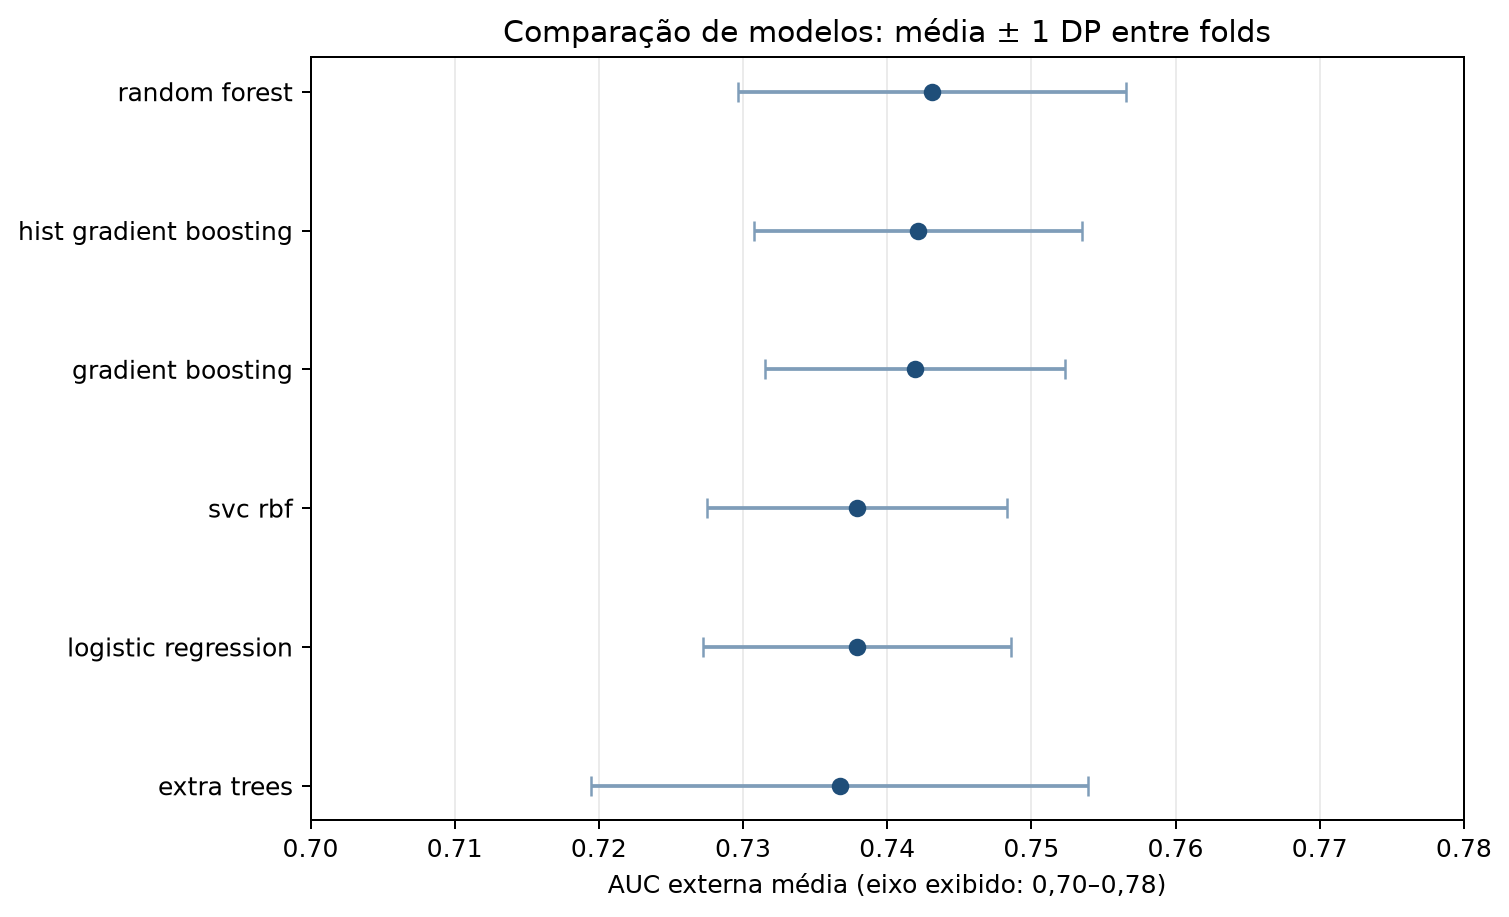

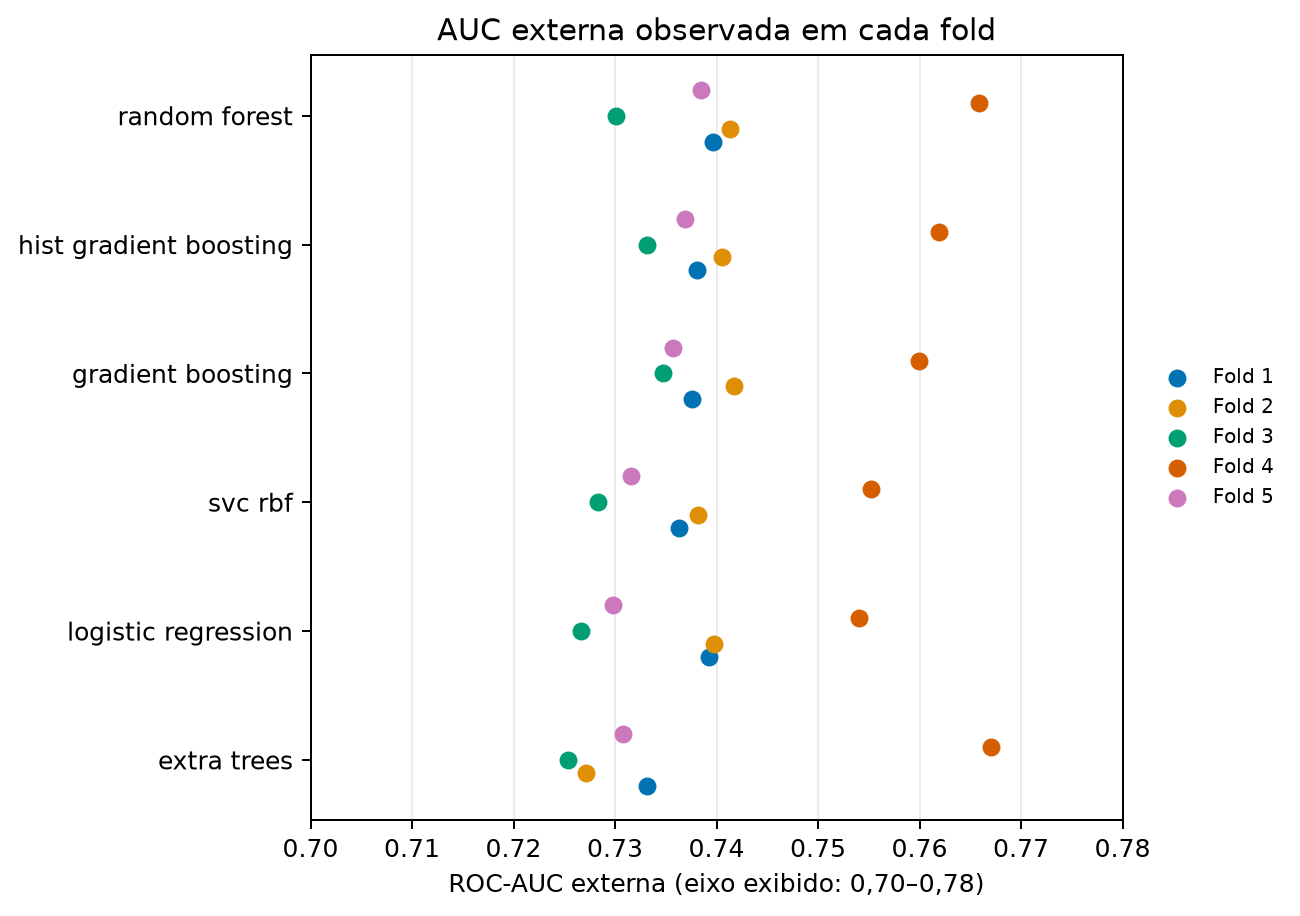

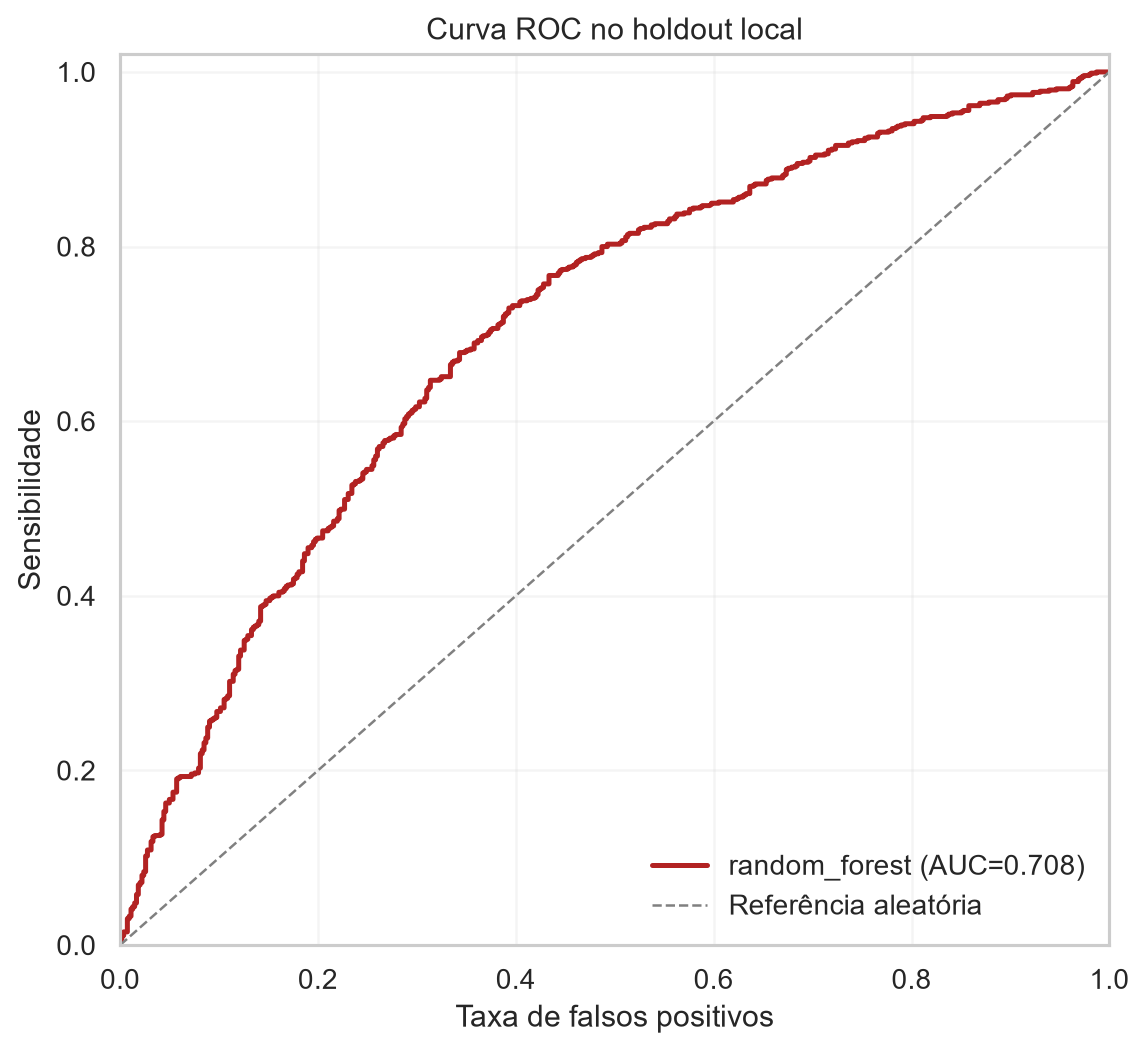

In [22]:
# 1) Médias da AUC externa com dispersão descritiva entre folds.
plot_table = nested_table.sort_values("AUC externa média", ascending=True).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8.5, 5.2))
y_positions = np.arange(len(plot_table))
ax.errorbar(
    plot_table["AUC externa média"], y_positions,
    xerr=plot_table["DP entre folds"], fmt="o", capsize=4,
    color="#1f4e79", ecolor="#7f9db9", markersize=6,
)
ax.set_yticks(y_positions, plot_table["Modelo"].str.replace("_", " "))
ax.set_xlim(0.70, 0.78)
ax.set_xlabel("AUC externa média (eixo exibido: 0,70–0,78)")
ax.set_title("Comparação de modelos: média ± 1 DP entre folds")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig(PROJECT_ROOT / "results" / "stage5_nested_auc_mean_sd.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

# 2) Scores brutos dos folds, exibidos como pontos sem impor ordem entre folds.
fig, ax = plt.subplots(figsize=(9, 5.2))
model_names = plot_table["Modelo"].tolist()
base_positions = np.arange(len(model_names))
fold_offsets = np.linspace(-0.20, 0.20, 5)
fold_colors = sns.color_palette("colorblind", n_colors=5)
for fold_index, (offset, color) in enumerate(zip(fold_offsets, fold_colors), start=1):
    fold_values = [
        stage4_results["nested_cv"][name]["outer_auc_by_fold"][fold_index - 1]
        for name in model_names
    ]
    ax.scatter(fold_values, base_positions + offset, color=color, s=38,
               label=f"Fold {fold_index}", zorder=3)
ax.set_yticks(base_positions, [name.replace("_", " ") for name in model_names])
ax.set_xlim(0.70, 0.78)
ax.set_xlabel("ROC-AUC externa (eixo exibido: 0,70–0,78)")
ax.set_title("AUC externa observada em cada fold")
ax.grid(axis="x", alpha=0.25)
ax.legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1.02, 0.5))
fig.tight_layout(rect=(0, 0, 0.82, 1))
fig.savefig(PROJECT_ROOT / "results" / "stage5_nested_auc_by_fold.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

# 3) Curva ROC do modelo selecionado no holdout reservado.
fpr, tpr, _ = roc_curve(y_holdout, holdout_prob, pos_label=1)
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot(fpr, tpr, color="#b22222", linewidth=2, label=f"{selected_model_name} (AUC={holdout_auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1, label="Referência aleatória")
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="Taxa de falsos positivos", ylabel="Sensibilidade", title="Curva ROC no holdout local")
ax.legend(loc="lower right", frameon=False)
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(PROJECT_ROOT / "results" / "stage5_selected_model_holdout_roc.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

stage5_results["plots"] = [
    "stage5_nested_auc_mean_sd.png",
    "stage5_nested_auc_by_fold.png",
    "stage5_selected_model_holdout_roc.png",
]
results_path.write_text(json.dumps(stage5_results, ensure_ascii=False, indent=2), encoding="utf-8")
print("Gráficos salvos na pasta results/.")

## 6. Interpretação dos resultados

### 6.1 Quais modelos foram mais promissores segundo o protocolo?
A interpretação final considerará a AUC externa aninhada, a dispersão entre folds e a avaliação local do candidato selecionado.

### 6.2 Quais padrões, diferenças ou comportamentos foram observados?
Verificar estabilidade entre folds, diferença entre busca interna e validação externa, matriz de confusão e erros de classificação.

### 6.3 O que os resultados sugerem sobre o problema e os dados?
Discutir apenas padrões preditivos observados. Importância de atributos e associações não demonstram causalidade nem efeito clínico.